In [278]:
import numpy as np
import pandas as pd 
import sklearn
import matplotlib.pyplot as plt

In [279]:
train = pd.read_csv('data/train.csv')
test = pd.read_csv('data/test.csv')

In [280]:
# my S-ka = 24072463
MY_SEED = 2463

# Stage 1 / Framing the problem



In [281]:
print('train shape', train.shape)
print('test shape', test.shape)

train shape (32940, 22)
test shape (8236, 20)


In [282]:
print(f'\n{train.dtypes}')


id                  int64
age                 int64
job                object
marital            object
education          object
default            object
housing            object
loan               object
contact            object
month              object
day_of_week        object
duration            int64
campaign            int64
pdays               int64
previous            int64
poutcome           object
emp.var.rate      float64
cons.price.idx    float64
cons.conf.idx     float64
euribor3m         float64
nr.employed       float64
y                  object
dtype: object


In [283]:
print(f'\n{test.dtypes}')


id                  int64
age                 int64
job                object
marital            object
education          object
default            object
housing            object
loan               object
contact            object
month              object
day_of_week        object
campaign            int64
pdays               int64
previous            int64
poutcome           object
emp.var.rate      float64
cons.price.idx    float64
cons.conf.idx     float64
euribor3m         float64
nr.employed       float64
dtype: object


**We predicting the column "y" or will they answer YES or NO** <br>
It's being predicted by columns describing features of a clients <br>
Limit in capacity means we need prioritise people that would say yes, because call centre may call only 10% of them

**In train dataset there'are two columns, that are not in train** <br>
"duraition" and "y"
<br><br>
They are not in train dataset, because 'duration' of the call is known only after the call. 'y' is yes or no, so it's also known only after the call

---
# Stage 2 \ Understanding the data

In [284]:
print(train['y'].value_counts())
print('\nlenght of the whole data ->', len(train))

print(f'accuracy of the model -> {(train["y"].value_counts()['no']/len(train))*100:.2f}%')
print('this model gives only 88.73% of NO answers')

y
no     29229
yes     3711
Name: count, dtype: int64

lenght of the whole data -> 32940
accuracy of the model -> 88.73%
this model gives only 88.73% of NO answers


In [285]:
for col in train.select_dtypes("object").columns:
    n = (train[col] == "unknown").sum()
    if n > 0:
        print(f"{col:15s}: {n:5d}       ({n/len(train)*100:.1f}%)")

job            :   275       (0.8%)
marital        :    64       (0.2%)
education      :  1401       (4.3%)
default        :  6871       (20.9%)
housing        :   794       (2.4%)
loan           :   794       (2.4%)


in other columns (where missing % is <5) we may use something like replacing it with most frequent, but we see that in "default" there's almost 21 percent of missing values. <br>
it means that bank doesn't usually know whether client has default or not. <br><br>

In [286]:
print(train[["month", "day_of_week"]].head(10))
print(train[["month", "day_of_week"]].tail(10))

  month day_of_week
0   may         tue
1   aug         mon
2   aug         fri
3   may         wed
4   jun         wed
5   aug         fri
6   may         thu
7   apr         fri
8   jul         wed
9   nov         thu
      month day_of_week
32930   nov         fri
32931   apr         thu
32932   nov         thu
32933   aug         mon
32934   jul         tue
32935   may         wed
32936   jul         mon
32937   may         tue
32938   jul         wed
32939   may         tue


we see that this calls are random, becuase there's a records from may, august, then suddenly june and then november. It means that they are mixed and random <br>
random split will not affect on us.

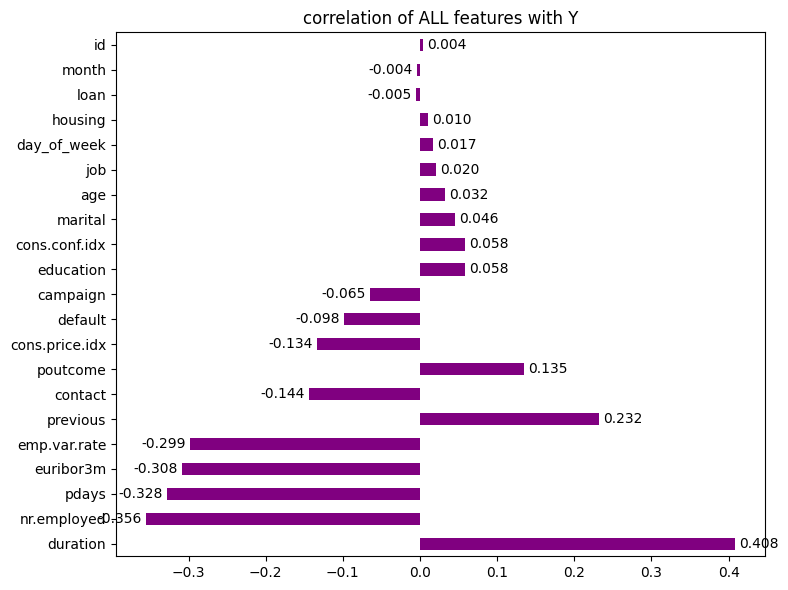

In [287]:
train_copy_1 = train.copy() # made a copy of train, in order to NOT change main train
y_yes = train_copy_1["y"].eq("yes")

for col in train_copy_1.select_dtypes(include=["object", "category"]).columns:
    train_copy_1[col] = train_copy_1[col].astype("category").cat.codes

all_corr = train_copy_1.drop(columns=["y"]).corrwith(y_yes).sort_values(key=abs, ascending=False)

plt.figure(figsize=(8, 6))

ax = all_corr.plot(kind="barh", color="purple")
ax.bar_label(ax.containers[0], fmt="%.3f", padding=3)

plt.title("correlation of ALL features with Y")
plt.tight_layout(); plt.show()

"duration" and "previous" columns has the strongest positive correlation among others = 0.408 . <br>
the highest **negative** correlation is on "pdays", "nr.employed" columns. <br>


---
# Stage 3 \ design


In [288]:
from sklearn.model_selection import train_test_split

X = train.drop(columns = ['y', 'duration'])
y = train['y']

X_train, X_holdout, y_train, y_holdout = train_test_split(
    X,y, test_size = 0.2, random_state = MY_SEED, stratify = y
)

print("X_train:", X_train.shape)
print("X_holdout:", X_holdout.shape)

print("\n'yes' share in X_train :", round((y_train == "yes").mean(), 3))
print("'yes' share in X_holdout:", round((y_holdout == "yes").mean(), 3))

X_train: (26352, 20)
X_holdout: (6588, 20)

'yes' share in X_train : 0.113
'yes' share in X_holdout: 0.113


yes share in separaten "train" and "holdout" data equals, that means that stratifying worked

In [289]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(n_splits = 5, shuffle = True, random_state = MY_SEED)

for fold, (training_index, validation_index) in enumerate(cv.split(X_train, y_train)):
    yes_mean = (y_train.iloc[validation_index] == 'yes').mean()
    print(f'Fold {fold+1}  / len = {len(validation_index)} / yes share = {yes_mean*100:.2f}%')

Fold 1  / len = 5271 / yes share = 11.27%
Fold 2  / len = 5271 / yes share = 11.27%
Fold 3  / len = 5270 / yes share = 11.25%
Fold 4  / len = 5270 / yes share = 11.27%
Fold 5  / len = 5270 / yes share = 11.27%


i will use StratifiedKFold, becuase our data is unbalanced (only 11% of yes answers). <br>
stratification will garantee that in each fold there'll be almost equal share of yes (maybe it will range on 0.01 +-).<br><br>

n_splits = 5 because it gives enough fold for checking our metrics, and smooth anomalies

---
# Stage 4

In [290]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

In [291]:
num_cols = ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate',
            'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
cat_cols = X_train.select_dtypes(include=["object", "category"]).columns

num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preproc = ColumnTransformer([
    ('num', num_pipe, num_cols),
    ('cat', cat_pipe, cat_cols)
])

In [292]:
if 'id' in X_train.columns:
    X_train = X_train.drop(columns=['id'])
if 'id' in X_holdout.columns:
    X_holdout = X_holdout.drop(columns=['id'])

before sending data to ML algorithm, these pipelines handles data: <br>
- it separates it into numerical and categorical columns, for numerical it cleans missing values with median, and standardize the scale with StandardScaler <br>
- for categorical, it fills missing values with mode(most frequent), and transforms it into binary format with OneHotEncoder <br><br>

In [293]:
fold_splits = list(cv.split(X_train, y_train))
training_index, validation_index = fold_splits[0]

X_train_fold = X_train.iloc[training_index]
X_val_fold   = X_train.iloc[validation_index]

In [294]:
preproc.fit(X_train_fold)

X_train_fold_tr = preproc.transform(X_train_fold)
X_val_fold_tr   = preproc.transform(X_val_fold)

scaler = preproc.named_transformers_['num']['scaler']
    
print(scaler.mean_[1])
print(X_train_fold['age'].mean())
print(X_val_fold['age'].mean())

2.5397751529813575
40.072102841421184
40.06033010813887


firstly we garantee simply by the fact that we used X_train_fold that is based on train data (X_train_fold). <br>
secondly, we see that scaler.mean and X_train_fold.mean on the column 'age' are equal, while validation mean is different. that means that validation values are NOT in the fit

**For NUMERICAL values:**<br>
- i will use median filling (SimpleImputer) <br>
- i will use StandardScaler for logistic regression and KNN <br>

**For CATEGORICAL values:**
- i will fill missing values with most frequent that appears (SimpleImputer), because the percantage of missing is < 5% (previous part) <br>
"default" with 20% of missed values has this feature not because of mistake or sth, but because bank just doesn't know about default. it would be risky to try to fill it with grouped mode or other method, because it in fact won't help the model.<br>
<br>
-OneHotEncoder for new categories, where'd be "ignore"

In [295]:
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression

In [296]:
pre_with_scale = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc",  StandardScaler())]), num_cols),
    ("cat", cat_pipe, cat_cols)
])
pipe_a = Pipeline([("pre", pre_with_scale),
                   ("clf", LogisticRegression(max_iter=1000, random_state=MY_SEED))])
scores_a = cross_val_score(pipe_a, X_train, y_train, cv=cv, scoring="roc_auc")

print(f"with StandardScaler:   mean = {scores_a.mean()}  std = {scores_a.std()}")



pre_no_scale = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", cat_pipe, cat_cols)
])
pipe_b = Pipeline([("pre", pre_no_scale),
                   ("clf", LogisticRegression(max_iter=1000, random_state=MY_SEED))])

scores_b = cross_val_score(pipe_b, X_train, y_train, cv=cv, scoring="roc_auc")

print(f"without StandardScaler:   mean = {scores_b.mean()}  std =  {scores_b.std()}")

with StandardScaler:   mean = 0.7912044786811788  std = 0.012165617457834512


c:\WORKING_FOLDER\PY_narxoz\TASK-3-MACHINE-LEARNING\.Burabayev_ML_task_3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\WORKING_FOLDER\PY_narxoz\TASK-3-MACHINE-LEARNING\.Burabayev_ML_task_3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale

without StandardScaler:   mean = 0.7896282093944614  std =  0.012776237257168801


c:\WORKING_FOLDER\PY_narxoz\TASK-3-MACHINE-LEARNING\.Burabayev_ML_task_3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


As we can see, there appeared ConvergenceWarning, that means that the N of iterations isn't enough. This directly shows that the pipe_b without StandardScaler is not capable to converge. <br>
this happens because there are sentinels and different scales among the features. linear regressions and KNN are very sensetive to the scale differences. <br><br>

In [297]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import FunctionTransformer

def clean(df):
    df = df.copy()
    df['pdays'] = df['pdays'].replace(999, -1)
    return df.replace('unknown', np.nan)

full_pipeline = Pipeline([
    ("clean", FunctionTransformer(clean)),
    ("pre", pre_with_scale),
    ("clf", LogisticRegression(max_iter=1000, random_state=MY_SEED))
])

full_pipeline.fit(X_train, y_train)

test_raw = pd.read_csv("data/test.csv", sep=",")

test_predictions = full_pipeline.predict_proba(test_raw)[:, 1]

print(test_predictions[:5])
print(test_predictions.min(), test_predictions.max(), test_predictions.mean())

[0.06193929 0.03308148 0.04231258 0.06583206 0.02605352]
0.005038294475564588 0.9254307746711501 0.10976843579681068


Pipeline succesfully processed the raw 'test.csv'

---
# Stage 5

In [299]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate

y_bin = (y_train == 'yes').astype(int)

models = {
    'majority class': DummyClassifier(strategy='prior'),
    'logistic regression': LogisticRegression(max_iter=1000, random_state=MY_SEED),
}

rows = []
for name, clf in models.items():
    pipe = Pipeline([('pre', preproc), ('clf', clf)])
    res = cross_validate(pipe, X_train, y_bin, cv=cv,
                         scoring=['accuracy', 'roc_auc', 'average_precision'])
    rows.append({
        'model': name,
        'accuracy': f"{res['test_accuracy'].mean():.3f} ± {res['test_accuracy'].std():.3f}",
        'roc_auc': f"{res['test_roc_auc'].mean():.3f} ± {res['test_roc_auc'].std():.3f}",
        'avg_precision': f"{res['test_average_precision'].mean():.3f} ± {res['test_average_precision'].std():.3f}",
    })

pd.DataFrame(rows).set_index('model')

,accuracy,roc_auc,avg_precision
model,,,
majority class,0.887 ± 0.000,0.500 ± 0.000,0.113 ± 0.000
logistic regression,0.900 ± 0.002,0.791 ± 0.012,0.451 ± 0.018


model where always no gives 88.7% but roc-auc 0.5. <br>
accuracy of this data is not correct.<br><br>

---
# Stage 6

In [300]:
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

candidates = [
    ("logreg", LogisticRegression(max_iter=1000, random_state=MY_SEED), {"clf__C": [0.1, 1, 10]}),
    ("knn", KNeighborsClassifier(), {"clf__n_neighbors": [25, 75]}),
    ("forest", RandomForestClassifier(n_estimators=100, random_state=MY_SEED, n_jobs=-1), {"clf__max_depth": [5, 10]}),
]

found = {}
for name, clf, grid in candidates:
    gs = GridSearchCV(Pipeline([("pre", preproc), ("clf", clf)]), grid, cv=cv, scoring="roc_auc")
    gs.fit(X_train, y_bin)
    i = gs.best_index_
    found[name] = gs
    print(name, gs.best_params_,
          "AUC = %.3f ± %.3f" % (gs.cv_results_["mean_test_score"][i], gs.cv_results_["std_test_score"][i]))

logreg {'clf__C': 0.1} AUC = 0.791 ± 0.012
knn {'clf__n_neighbors': 75} AUC = 0.781 ± 0.014
forest {'clf__max_depth': 10} AUC = 0.800 ± 0.010


In [301]:
best_C = found["logreg"].best_params_["clf__C"]

for cw in [None, "balanced"]:
    pipe = Pipeline([("pre", preproc),
                     ("clf", LogisticRegression(C=best_C, class_weight=cw, max_iter=1000, random_state=MY_SEED))])
    s = cross_val_score(pipe, X_train, y_bin, cv=cv, scoring="roc_auc")
    print("class_weight =", cw, "AUC = %.3f ± %.3f" % (s.mean(), s.std()))

class_weight = None AUC = 0.791 ± 0.012
class_weight = balanced AUC = 0.792 ± 0.012


all three models score between 0.78 and 0.80 roc-auc, and the fold std is 0.01-0.014. <br>
random forest (0.800) is ahead of logistic regression (0.791) by 0.009, which is smaller than std, so i don't call it the winner.<br>
knn is the weakest <br>
only forest vs knn (0.019) is kinda bigger than the spread <br><br>

class_weight='balanced' changed auc by only 0.001, which is far lower than std. <br>
this is expected because class weights mostly change the decision threshold <br><br>

i choose logistic regression because it's the simplest and easiest model to explain

---
# Stage 7

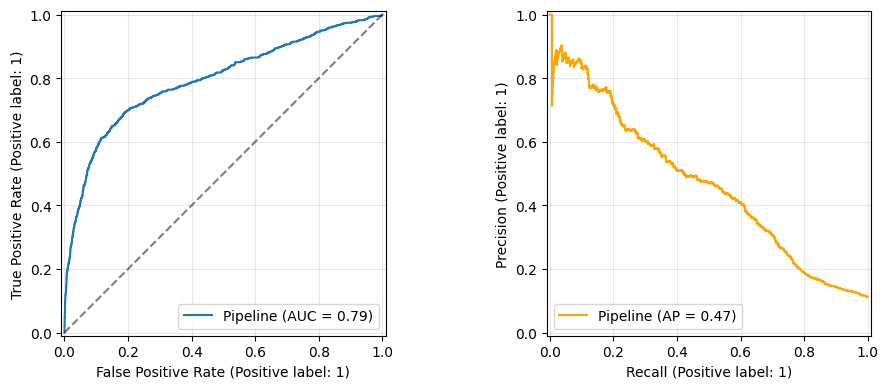

In [303]:
import matplotlib.pyplot as plt
from sklearn.metrics import PrecisionRecallDisplay, RocCurveDisplay

# 1. Обучение
pipe = Pipeline([
    ("pre", preproc),
    ("clf", LogisticRegression(C=best_C, max_iter=1000, random_state=MY_SEED))
]).fit(X_train, y_bin)

y_holdout_bin = (y_holdout == "yes").astype(int)

# 2. Отрисовка ROC и PR кривых
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

RocCurveDisplay.from_estimator(pipe, X_holdout, y_holdout_bin, ax=ax1)
ax1.plot([0, 1], [0, 1], "k--", alpha=0.5)
ax1.grid(True, alpha=0.3)

PrecisionRecallDisplay.from_estimator(pipe, X_holdout, y_holdout_bin, ax=ax2, color="orange")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix, precision_score, recall_score

scores = pipe.predict_proba(X_holdout)[:, 1]
cutoff = np.percentile(scores, 90)
y_pred = (scores >= cutoff).astype(int)

tn, fp, fn, tp = confusion_matrix(y_holdout_bin, y_pred).ravel()
prec = precision_score(y_holdout_bin, y_pred)
rec = recall_score(y_holdout_bin, y_pred)
base_rate = y_holdout_bin.mean()


print(f"""
Cutoff score:    {cutoff:.4f}
Clients called:  {y_pred.sum()} / {len(y_pred)} ({y_pred.mean():.1%})
Precision:       {prec:.3f} ({prec:.1%})
Recall:          {rec:.3f} ({rec:.1%})
Base rate:       {base_rate:.3f} ({base_rate:.1%})
Lift over rand:  {prec / base_rate:.2f}x

Confusion Matrix:
[[TN={tn:<6} FP={fp}]
 [FN={fn:<6} TP={tp}]]
""")


Cutoff score:    0.3085
Clients called:  659 / 6588 (10.0%)
Precision:       0.492 (49.2%)
Recall:          0.437 (43.7%)
Base rate:       0.113 (11.3%)
Lift over rand:  4.37x

Confusion Matrix:
[[TN=5511   FP=335]
 [FN=418    TP=324]]



**Call Center Results (Top 10% targeted: 659 / 6,588 clients)**

* **TP (324):** Successful calls. Precision is 49.2% — almost every second call converts.
* **FP (335):** Calls spent on clients who declined.
* **TN (5,511):** Non-buyers correctly skipped, saving team capacity.
* **FN (418):** Potential sales missed due to the 10% cutoff limit.
* **Lift (4.37x):** Random calling yields ~74 sales (11.3% base rate). Targeting top 10% yields 324 sales — 4.4x better than random.

**Limitation: Random Split Risk**

* In production, the model trains on past data to predict future calls.
* The 2008–2010 dataset covers major macroeconomic shifts (interest rates, employment).
* Random splitting mixes all years across train and test, testing the model on the same market state it trained on.
* A realistic time split (train 2008–2009, test 2010) would likely yield lower real-world AUC and precision due to macro drift.

---
# Stage 8

In [305]:
import joblib
from sklearn.base import clone

X_all = train.drop(columns=['id', 'y', 'duration'])
y_all = (train['y'] == 'yes').astype(int)

final_pipe = Pipeline([
    ('pre', clone(preproc)),
    ('clf', LogisticRegression(C=best_C, max_iter=1000, random_state=MY_SEED))
])
final_pipe.fit(X_all, y_all)
joblib.dump(final_pipe, 'model.joblib')

test_raw = pd.read_csv('data/test.csv')
scores = final_pipe.predict_proba(test_raw.drop(columns=['id']))[:, 1]
cutoff = np.percentile(scores, 90)          # 10 % rule
pred = (scores >= cutoff).astype(int)

pd.DataFrame({'id': test_raw['id'], 'y_pred': pred, 'y_score': scores}) \
  .to_csv('predictions.csv', index=False)

loaded = joblib.load('model.joblib')
print(np.allclose(loaded.predict_proba(test_raw.drop(columns=['id']))[:, 1], scores))
print(pred.sum(), 'of', len(pred), 'clients to call')

True
824 of 8236 clients to call
